## Problem 2: Calculating NDVI (12 points)

In this problem, we will work with the same satellite imagery data as we used during the lesson. Specifically, we will explore the Sentinel-2 satellite image from Nuuksio National Park in Finland. The data is obtained from the [Copernicus Data Space Ecosystem](https://dataspace.copernicus.eu). Our objective is to explore, process the data, and ultimately calculate the NDVI (Normalized Difference Vegetation Index).

### What is NDVI?

NDVI (Normalized Difference Vegetation Index) is a simple, widely used index for assessing vegetation health and coverage based on satellite imagery. NDVI is calculated by comparing the Near Infrared (NIR) and Red bands of satellite data. Vegetation reflects more NIR light and absorbs more visible red light, so the NDVI value provides insight into the density and health of vegetation.

The formula to calculate NDVI is:

$$
NDVI = \frac{(NIR - Red)}{(NIR + Red)}
$$

- **NIR (Near Infrared)** corresponds to Band 8 for Sentinel-2 imagery.
- **Red** corresponds to Band 4 for Sentinel-2 imagery.

NDVI values range from -1 to +1, where higher values indicate healthier and denser vegetation.

### Sentinel-2 Band Reference

For Sentinel-2 imagery, the bands are predefined and consistent across products. Here is a quick reference for the Sentinel-2 bands:

| **Band**   | **Description**                     | **Wavelength (nm)** |
|------------|-------------------------------------|---------------------|
| Band 1     | Coastal aerosol                     | 443 nm              |
| Band 2     | Blue                                | 490 nm              |
| Band 3     | Green                               | 560 nm              |
| Band 4     | Red                                 | 665 nm              |
| Band 5     | Vegetation Red Edge                 | 705 nm              |
| Band 6     | Vegetation Red Edge                 | 740 nm              |
| Band 7     | Vegetation Red Edge                 | 783 nm              |
| Band 8     | Near Infrared                       | 842 nm              |
| Band 8A    | Narrow Near Infrared                | 865 nm              |
| Band 9     | Water Vapor                         | 945 nm              |
| Band 10    | Short-Wave Infrared – Cirrus        | 1375 nm             |
| Band 11    | Short-Wave Infrared                 | 1610 nm             |
| Band 12    | Short-Wave Infrared                 | 2190 nm             |

## (2a) - Read the raster and get the metadata (1 point)

As the first step read the raster file from data directory `data/sentinel2_Nuuksio_small.tif` as `sentinel_raster`. Provide the following information from the raster (use the same variable names and format):

```
data_crs = "the CRS of our raster data"
resolution = "as string in this format X*Y"
total_pixels = "total number of pixels across all bands as integer"
```

Remember to print the values. 

In [1]:
import rioxarray

raster_file = 'data/sentinel2_Nuuksio_small.tif'

sentinel_raster = rioxarray.open_rasterio(raster_file)

data_crs = sentinel_raster.rio.crs
resolution = (f"{sentinel_raster.rio.resolution()[0]}*{sentinel_raster.rio.resolution()[1]}")
total_pixels = sentinel_raster.size

print(f"The CRS of our raster data: {data_crs}")
print(f"Resolution: {resolution}")
print(f"Total number of pixels across all bands: {total_pixels}")
sentinel_raster.shape

The CRS of our raster data: EPSG:32635
Resolution: 10.000423406593432*-9.998319640387246
Total number of pixels across all bands: 7895160


(12, 723, 910)

## (2b) - Map NIR and RED bands (2 points)

Visualize the Near Infrared (NIR) and Red bands as individual raster plots (use subplots). You can decide what color you want to us efor your visulizations. 

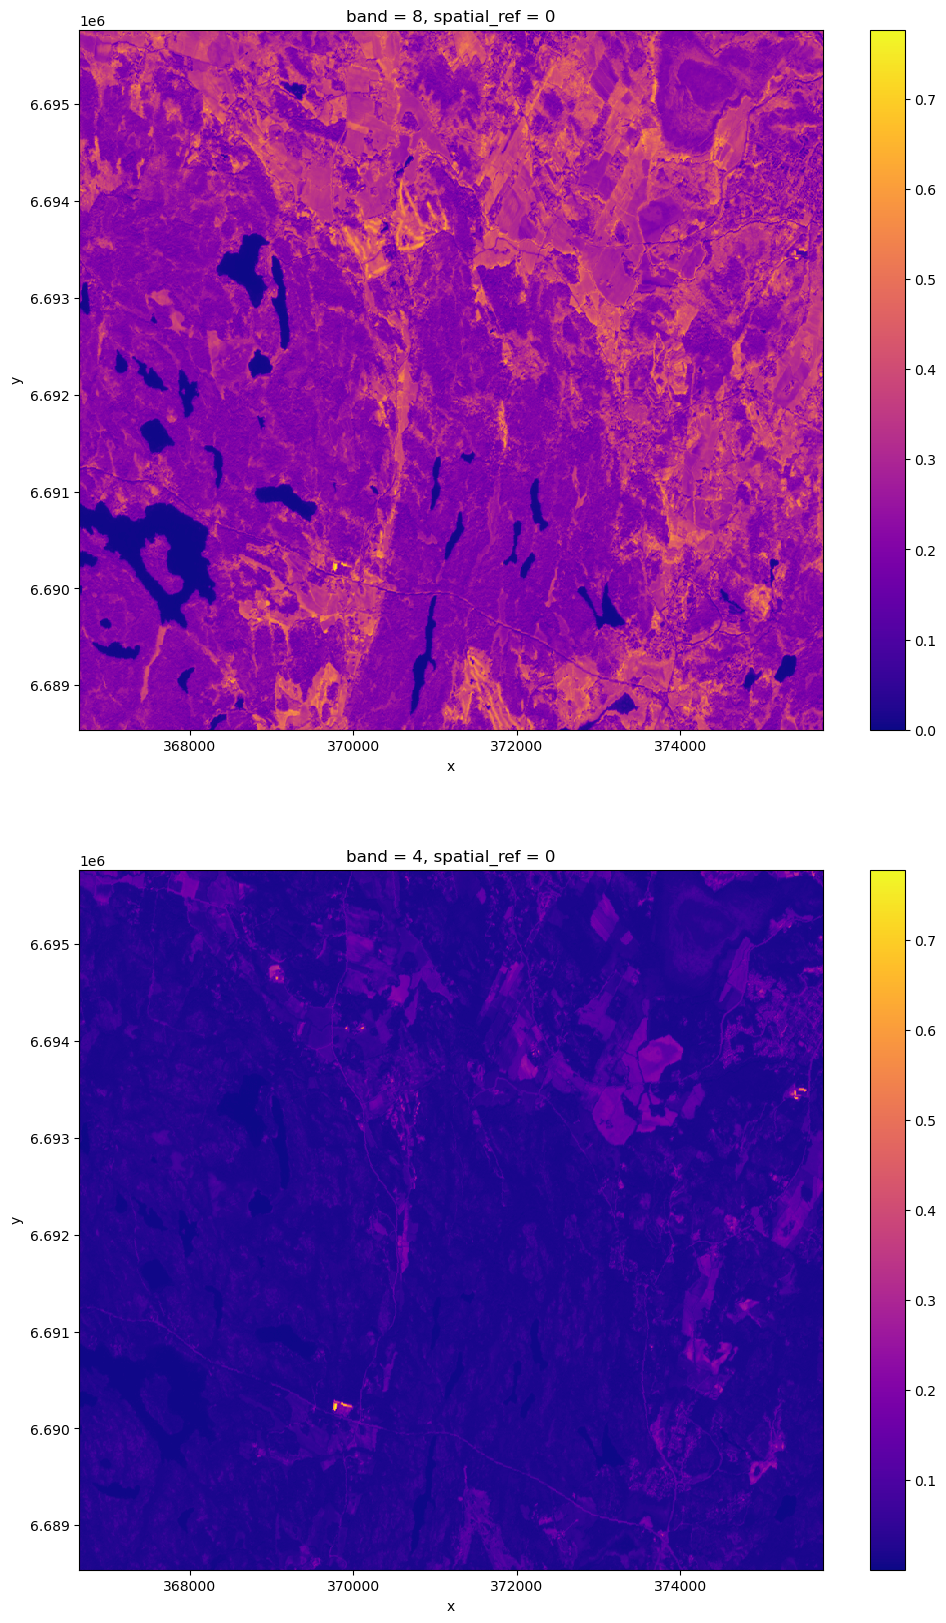

In [2]:
import matplotlib 
import matplotlib.pyplot as plt

nir_band = sentinel_raster.sel(band=8)
red_band = sentinel_raster.sel(band=4)

fig, axes= plt.subplots(2, figsize=(12, 20))

nir_band.plot(ax=axes[0], cmap='plasma')
red_band.plot(ax=axes[1], cmap='plasma')

## (2c) - Calculate the NDVI (5 points)

Calculate the NDVI using the formula provided above. Store the resulting raster as `NDVI` and export it as `NDVI.tif`. Finally, plot the NDVI raster. 


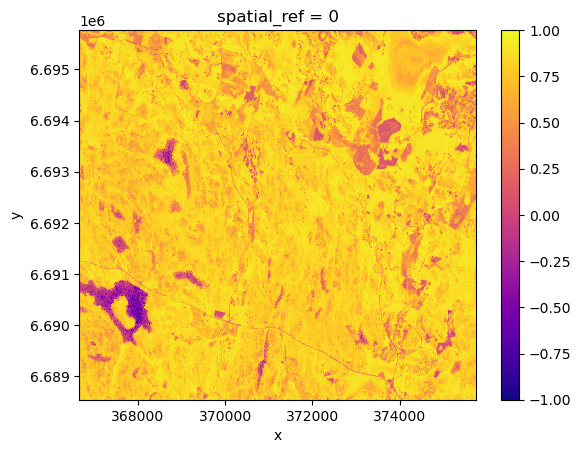

In [3]:
NDVI = (nir_band - red_band)/(nir_band + red_band)

NDVI.rio.to_raster('NDVI.tif')

NDVI.plot(cmap= 'plasma')

## (2d) - Reclassify the NDVI raster (4 points)

In this task, you will reclassify the NDVI values into distinct vegetation categories and visualize the result.

1. **Reclassify the NDVI values**: 
   - Create the following NDVI classification:
     - NDVI < 0.2: **Non-Vegetated**
     - 0.2 ≤ NDVI < 0.5: **Sparse Vegetation**
     - 0.5 ≤ NDVI: **Dense Vegetation**
   - Use appropriate values to represent each class (1 for Non-Vegetated, 2 for Sparse Vegetation, 3 for Dense Vegetation).

2. **Visualize the Reclassified NDVI**: 
   - Plot the reclassified NDVI using a discrete color map where each class has a distinct color.
   - Use a suitable color scheme to clearly differentiate between the classes (e.g., brown for Non-Vegetated, yellow for Sparse Vegetation, green for Dense Vegetation).




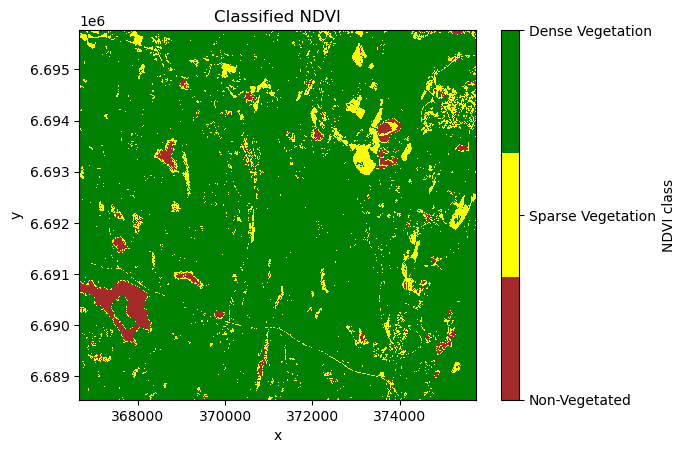

In [35]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

# Define the bins and new class values
bins = [0.2, 0.5, 1]  # Bins for NDVI classification
new_values = [1, 2, 3]  # Class values: 1 for  Non-Vegetated, 2 for Sparse Vegetation, 3 for Dense Vegetation

# Apply the reclassification
reclassified_raster = np.digitize(NDVI, bins, right=True)


# Convert to an xarray DataArray
reclassified_raster = xr.DataArray(
    reclassified_raster,
    dims=NDVI.dims,  # Keep the same dimensions
    coords=NDVI.coords,  # Retain the spatial coordinates
    attrs=NDVI.attrs  # Preserve the original attributes
)
# Plot using xarray's plot method
plot = reclassified_raster.plot(cmap=plt.matplotlib.colors.ListedColormap(['brown', 'yellow', 'green']))


colorbar = plot.colorbar
colorbar.set_ticks([0, 1, 2])
colorbar.set_ticklabels(['Non-Vegetated', 'Sparse Vegetation', 'Dense Vegetation'])  # Rename the labels
colorbar.set_label("NDVI class")

plt.title("Classified NDVI")
plt.show()

### **Answer these questions**:
   - Q1: How does the distribution of vegetation classes compare across the area?
   - Q2: Are there more areas with sparse or dense vegetation?

The area is covered mostly be dense vegettion. Areas with sparce vegetation are concentrated in the Eastern and Northern parts of the area. There are some non-vegetated patches across the area, the biggest one is in the South-East of the area.


## (2e) Optional Raster value histogram - (0 point)

Use your previous skills with `matplotlib` to create a histogram of the raster values from the original NDVI raster (before reclassification). The histogram should visualize the distribution of NDVI values across the dataset, providing insights into the spread and frequency of different vegetation index values. Customize the bins and labels as needed to make the plot clear and informative.


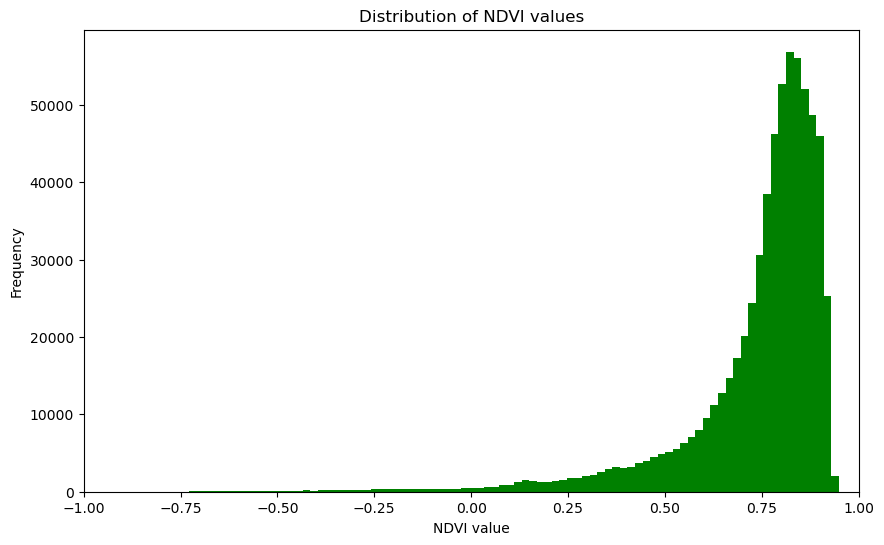

In [33]:
# Plot a histogram
f, ax = plt.subplots(figsize=(10, 6))
NDVI.plot.hist(ax=ax,
       color="green",
              bins = 100
              )
ax.set(title="Distribution of NDVI values",
       xlabel='NDVI value',
       ylabel='Frequency')
ax.set_xlim(xmin=-1, xmax=1)
plt.show()